# LeukoGuard — Member 1, Part C: Feature Engineering (derived CBC ratios)

**Goal.** Build clinically motivated ratio features from the cleaned CBC, check that they are **valid** (computed correctly, sensible ranges, no division errors) and get a first look at whether they are **useful** for separating leukemia from healthy.
Their real added value over the raw counts is tested formally in **Part E (RQ3)**.

| Feature | Formula | Clinical meaning |
|---|---|---|
| **NLR** | NEUT# / LYMPH# | Neutrophil-to-lymphocyte ratio; systemic inflammation / myeloid vs lymphoid balance |
| **PLR** | PLT / LYMPH# | Platelet-to-lymphocyte ratio |
| **MLR** | MONO# / LYMPH# | Monocyte-to-lymphocyte ratio |
| **SII** | PLT × NEUT# / LYMPH# | Systemic immune-inflammation index |
| **dNLR** | NEUT# / (WBC − NEUT#) | "Derived NLR": usable when only WBC and neutrophils are reported |

**Leakage note.** Each ratio is a fixed row-wise formula with no parameters learned from data, so it is safe to add to every cohort before splitting.
A constant **ε = 0.01 ×10⁹/L** (the analyser's reporting resolution) is added to every denominator, because LYMPH# = 0 occurs (mostly in leukemia) and would otherwise give ∞.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
from leuko_common import (FEATURES, CORE_FEATURES, DERIVED, DERIVED_DEFS, DERIVED_REFERENCE, EPS,
                          load_clean, add_derived_features)

FIG_DIR = ROOT / "reports" / "figures"; TAB_DIR = ROOT / "reports" / "tables"
FEAT_DIR = ROOT / "data" / "features"; FEAT_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_HC, C_LK = "#2a78d6", "#eb6834"
def savefig(name): plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## C1. Compute the derived features on all cohorts

In [2]:
clean = load_clean(ROOT / "data" / "cleaned" / "leukoalert_cleaned.csv.gz")
fe = add_derived_features(clean)
print("Shape before:", clean.shape, " after:", fe.shape)
pd.DataFrame([(k, v[0], DERIVED_REFERENCE[k]) for k, v in DERIVED_DEFS.items()], columns=["feature", "formula", "reference"])

Shape before: (446637, 77)  after: (446637, 82)


,feature,formula,reference
0,NLR,NEUT# / (LYMPH# + 0.01),Neutrophil-to-lymphocyte ratio; normal adult range roughly 0.8-3.5
1,PLR,PLT / (LYMPH# + 0.01),Platelet-to-lymphocyte ratio; normal roughly 50-200
2,MLR,MONO# / (LYMPH# + 0.01),Monocyte-to-lymphocyte ratio; normal roughly 0.1-0.35
3,SII,PLT x NEUT# / (LYMPH# + 0.01),Systemic immune-inflammation index (PLT x NLR); normal roughly 200-700
4,dNLR,NEUT# / (WBC - NEUT# + 0.01),Derived NLR: neutrophils / (all other white cells)


## C2. Validity checks
### C2.1 Computation check: NLR must equal NEUT% / LYMPH%
NEUT# / LYMPH# and NEUT% / LYMPH% are the same ratio (both counts share the WBC denominator). Computing it a second, independent way checks the formula and the column mapping.

In [3]:
chk = fe[["NLR", "NEUT%", "LYMPH%", "LYMPH#"]].dropna()
chk = chk[chk["LYMPH#"] >= 0.5]                      # away from the epsilon / rounding zone
nlr_pct = chk["NEUT%"] / chk["LYMPH%"]
rel = (chk["NLR"] - nlr_pct).abs() / nlr_pct
print(f"Records compared: {len(chk):,}")
print(f"Spearman ρ(NLR from counts, NLR from %) = {stats.spearmanr(chk['NLR'], nlr_pct)[0]:.4f}")
print(f"Median relative difference = {100*rel.median():.2f}%  |  95th pct = {100*rel.quantile(.95):.2f}%  (rounding of reported values)")

Records compared: 396,819
Spearman ρ(NLR from counts, NLR from %) = 1.0000
Median relative difference = 0.70%  |  95th pct = 1.75%  (rounding of reported values)


### C2.2 Missing values, infinities, negatives, and the effect of ε

In [4]:
rows = []
for f in DERIVED:
    s = fe[f]
    rows.append({"feature": f, "missing_%": 100 * s.isna().mean(), "inf": int(np.isinf(s).sum()),
                 "negative": int((s < 0).sum()), "min": s.min(), "median": s.median(), "max": s.max()})
val = pd.DataFrame(rows).set_index("feature")
display(val.round(3))
lz = fe["LYMPH#"] == 0
print(f"Records with LYMPH# = 0: {lz.sum():,} ({100*lz.mean():.2f}%), of which leukemia: {100*fe.loc[lz,'y'].mean():.1f}%")
print("Their NLR (=NEUT#/0.01) median:", fe.loc[lz, "NLR"].median(), "→ very large but finite. The log transform + training-fold clipping in the LR pipeline limits their leverage.")
print("\nMissing derived ratio ⇔ missing component (differential not performed):",
      bool((fe["NLR"].isna() == (fe["NEUT#"].isna() | fe["LYMPH#"].isna())).all()))

,missing_%,inf,negative,min,median,max
feature,,,,,,
NLR,0.886,0,0,0.0,3.221,4469.0
PLR,0.886,0,0,0.0,145.087,48700.0
MLR,0.886,0,0,0.0,0.336,403.0
SII,0.886,0,0,0.0,640.879,712152.0
dNLR,0.886,0,0,0.0,2.138,777.0


Records with LYMPH# = 0: 639 (0.14%), of which leukemia: 56.2%
Their NLR (=NEUT#/0.01) median: 36.0 → very large but finite. The log transform + training-fold clipping in the LR pipeline limits their leverage.

Missing derived ratio ⇔ missing component (differential not performed): True


### C2.3 Plausibility: do healthy records fall in the published reference ranges?

In [5]:
dev = fe[fe["cohort"] == "development"].reset_index(drop=True)
ref = {"NLR": (0.78, 3.53), "PLR": (50, 200), "MLR": (0.1, 0.35), "SII": (200, 700), "dNLR": (0.5, 2.5)}
pl = []
for f, (lo, hi) in ref.items():
    for k, lab in [(0, "healthy"), (1, "leukemia")]:
        s = dev.loc[dev.y == k, f].dropna()
        pl.append({"feature": f, "class": lab, "median": s.median(), "IQR": f"{s.quantile(.25):.2f} – {s.quantile(.75):.2f}",
                   "% inside reference": 100 * s.between(lo, hi).mean(), "reference range": f"{lo} – {hi}"})
pd.DataFrame(pl).round(2)

,feature,class,median,IQR,% inside reference,reference range
0,NLR,healthy,4.02,2.11 – 8.51,41.85,0.78 – 3.53
1,NLR,leukemia,1.74,0.35 – 5.94,29.94,0.78 – 3.53
2,PLR,healthy,158.94,107.75 – 250.00,59.81,50 – 200
3,PLR,leukemia,100.00,38.33 – 254.55,38.65,50 – 200
4,MLR,healthy,0.38,0.23 – 0.67,41.80,0.1 – 0.35
5,MLR,leukemia,0.29,0.07 – 1.00,23.29,0.1 – 0.35
6,SII,healthy,799.31,406.45 – 1663.90,36.77,200 – 700
7,SII,leukemia,82.40,8.85 – 455.03,18.71,200 – 700
8,dNLR,healthy,2.58,1.52 – 4.80,46.25,0.5 – 2.5
9,dNLR,leukemia,1.04,0.26 – 2.76,38.60,0.5 – 2.5


**Reading (C2).** The ratios are computed correctly: count-based NLR agrees with %-based NLR (ρ ≈ 1; the small differences are rounding of reported values). There are **no infinities or negative values**.
A ratio is missing exactly when its components are (the differential was not performed), and the pipeline's imputer and missing-indicator handle that.
Only 37–60% of healthy controls fall inside the textbook adult ranges, and their medians sit above them (NLR 4.0 vs ≤ 3.5; SII 799 vs ≤ 700).
This is plausible: the "healthy" class means **non-leukemia hospital patients**, not screened volunteers, so infection and inflammation raise NLR and SII. It should be stated when interpreting these ratios.

## C3. Usefulness (development set only)
### C3.1 Distributions by class

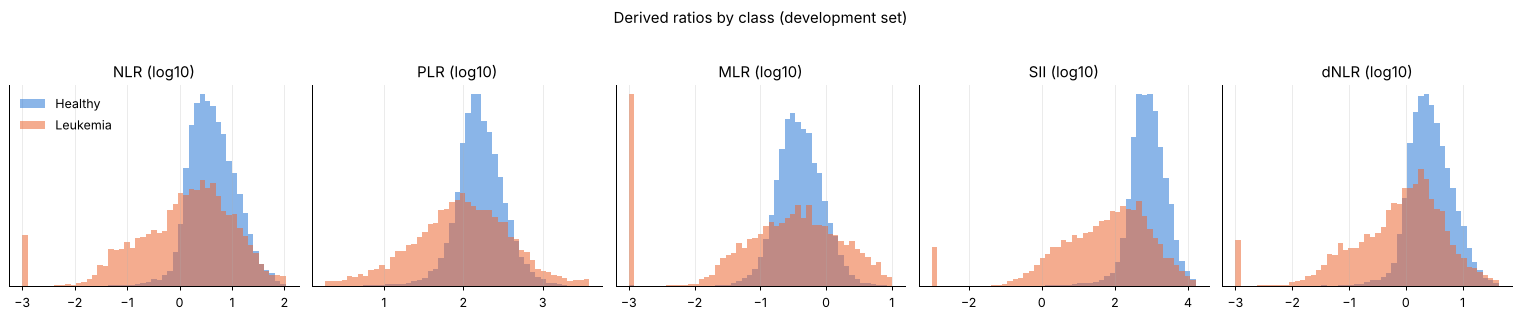

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, f in zip(axes, DERIVED):
    s = dev[[f, "y"]].dropna()
    v = np.log10(s[f] + 1e-3)
    bins = np.linspace(*np.nanpercentile(v, [0.5, 99.5]), 50)
    for k, c, lab in [(0, C_HC, "Healthy"), (1, C_LK, "Leukemia")]:
        ax.hist(v[s.y == k], bins=bins, density=True, alpha=.55, color=c, label=lab)
    ax.set_title(f"{f} (log10)"); ax.set_yticks([])
axes[0].legend(frameon=False)
fig.suptitle("Derived ratios by class (development set)", y=1.03)
plt.tight_layout(); savefig("C3_derived_distributions"); plt.show()

### C3.2 Univariate discrimination: derived ratio vs its own components
**ROC-AUC** of each single feature (orientation-free: max(AUC, 1−AUC); 0.5 = useless, 1 = perfect) and **Cliff's δ**.
A ratio is useful on its own if it separates better than the counts it is built from.

In [7]:
def uni(f):
    s = dev[[f, "y"]].dropna()
    auc = roc_auc_score(s.y, s[f])
    a, b = s.loc[s.y == 1, f], s.loc[s.y == 0, f]
    U = stats.mannwhitneyu(a, b).statistic
    return {"feature": f, "AUC (oriented)": max(auc, 1 - auc), "direction in leukemia": "higher" if auc > .5 else "lower",
            "cliffs_delta": 2 * U / (len(a) * len(b)) - 1}

comp = {"NLR": ["NEUT#", "LYMPH#", "NEUT%", "LYMPH%"], "PLR": ["PLT", "LYMPH#"], "MLR": ["MONO#", "LYMPH#", "MONO%"],
        "SII": ["PLT", "NEUT#", "LYMPH#"], "dNLR": ["NEUT#", "WBC", "NEUT%"]}
rows = []
for f, cs in comp.items():
    r = uni(f); r["group"] = f; r["role"] = "DERIVED"; rows.append(r)
    for c in cs:
        r = uni(c); r["group"] = f; r["role"] = "component"; rows.append(r)
ut = pd.DataFrame(rows)[["group", "role", "feature", "AUC (oriented)", "direction in leukemia", "cliffs_delta"]]
ut.round(3).to_csv(TAB_DIR / "C3_univariate_derived_vs_components.csv", index=False)
best_comp = ut[ut.role == "component"].groupby("group")["AUC (oriented)"].max()
summ = ut[ut.role == "DERIVED"].set_index("group")[["AUC (oriented)", "direction in leukemia", "cliffs_delta"]]
summ["best component AUC"] = best_comp
summ["gain vs best component"] = summ["AUC (oriented)"] - summ["best component AUC"]
display(summ.round(3))
ut.round(3)

,AUC (oriented),direction in leukemia,cliffs_delta,best component AUC,gain vs best component
group,,,,,
NLR,0.670,lower,-0.340,0.828,-0.158
PLR,0.625,lower,-0.250,0.863,-0.238
MLR,0.566,lower,-0.131,0.763,-0.197
SII,0.805,lower,-0.610,0.863,-0.058
dNLR,0.714,lower,-0.429,0.828,-0.114


,group,role,feature,AUC (oriented),direction in leukemia,cliffs_delta
0,NLR,DERIVED,NLR,0.670,lower,-0.340
1,NLR,component,NEUT#,0.828,lower,-0.657
2,NLR,component,LYMPH#,0.763,lower,-0.526
3,NLR,component,NEUT%,0.709,lower,-0.418
4,NLR,component,LYMPH%,0.633,higher,0.266
5,PLR,DERIVED,PLR,0.625,lower,-0.250
6,PLR,component,PLT,0.863,lower,-0.726
7,PLR,component,LYMPH#,0.763,lower,-0.526
8,MLR,DERIVED,MLR,0.566,lower,-0.131
9,MLR,component,MONO#,0.687,lower,-0.375


### C3.3 Redundancy: how much of each ratio is already in the raw features?
1. Highest Spearman |ρ| with any raw feature (is a rank-equivalent copy already in the data?).
2. **Linear reconstructability** (R² of a linear regression of the ratio on raw inputs):
   * on the raw scale from its own components (what an LR on untransformed counts could rebuild),
   * on the **LR pipeline's log1p scale** from its components, and from **all 71 log-transformed raw features**.
   log(NEUT#/LYMPH#) = log NEUT# − log LYMPH#, so on a log scale a ratio is close to a linear combination of inputs the LR already has.

In [8]:
from sklearn.linear_model import LinearRegression
from leuko_common import LOG_FEATURES
Z = dev[FEATURES].copy()
L = [c for c in LOG_FEATURES if c in FEATURES]
Z[L] = np.log1p(Z[L].clip(lower=0)); Z = Z.fillna(Z.median())
def r2(Xm, t):
    return LinearRegression().fit(Xm, t).score(Xm, t)
rows = []
for f, cs in {"NLR": ["NEUT#", "LYMPH#"], "PLR": ["PLT", "LYMPH#"], "MLR": ["MONO#", "LYMPH#"],
              "SII": ["PLT", "NEUT#", "LYMPH#"], "dNLR": ["NEUT#", "WBC"]}.items():
    s = dev[[f] + cs].dropna(); m = dev[f].notna()
    rho = dev[FEATURES].corrwith(dev[f], method="spearman").abs()
    rows.append({"feature": f, "most similar raw feature": rho.idxmax(), "max |ρ|": rho.max(),
                 "R² raw scale (components)": r2(s[cs], s[f]),
                 "R² log1p (components)": r2(np.log1p(s[cs]), np.log1p(s[f])),
                 "R² log1p (all 71 raw)": r2(Z[m], np.log1p(dev.loc[m, f]))})
red = pd.DataFrame(rows).set_index("feature")
red.round(3).to_csv(TAB_DIR / "C3_redundancy.csv")
red.round(3)

,most similar raw feature,max |ρ|,R² raw scale (components),R² log1p (components),R² log1p (all 71 raw)
feature,,,,,
NLR,LYMPH%,0.979,0.025,0.804,0.935
PLR,NEUT%&,0.573,0.011,0.839,0.929
MLR,LYMPH%&,0.676,0.068,0.645,0.800
SII,NEUT%&,0.844,0.083,0.908,0.980
dNLR,NEUT%,0.998,0.039,0.639,0.939


**Reading (C3).**
* All five ratios separate the classes, and all are **lower** in leukemia: neutrophils fall more than lymphocytes (relative lymphocytosis), and platelets collapse (PLR, SII).
* **No ratio beats its best component on its own.** PLT, NEUT# and WBC separate better than any single ratio (negative "gain vs best component"). SII comes closest (AUC 0.81) because it combines PLT and neutrophils.
* **NLR and dNLR are near copies of existing columns.** NLR ranks almost identically to LYMPH% (|ρ| = 0.98), and dNLR to NEUT% (|ρ| = 0.998), because NEUT# / LYMPH# = NEUT% / LYMPH%.
* **Redundancy depends on the scale.** On the raw scale a linear model can rebuild almost none of the ratios from their components (R² ≤ 0.08), so to a raw-scale LR a ratio is a genuinely new, non-linear input.
  After the LR pipeline's log1p transform, 80–98% of each ratio's variance is a linear combination of the 71 raw features.
  **Prediction for RQ3:** small or no gain from ratios in our log-transformed LR, a clearer gain in an LR on untransformed counts, and possibly for tree models (Members 2/3). Part E tests this formally.

## C4. Save the feature-engineered dataset

In [9]:
out = FEAT_DIR / "leukoalert_features.csv.gz"
fe.to_csv(out, index=False, compression="gzip")
dev.to_csv(FEAT_DIR / "features_development.csv", index=False)
print("Saved:", out.name, fe.shape, "| features_development.csv", dev.shape)
print("Feature lists available in src/leuko_common.py: FEATURES (71 raw), CORE_FEATURES (24 routine CBC), DERIVED (5 ratios)")

Saved: leukoalert_features.csv.gz (446637, 82) | features_development.csv (26922, 82)
Feature lists available in src/leuko_common.py: FEATURES (71 raw), CORE_FEATURES (24 routine CBC), DERIVED (5 ratios)
